# Model Experiments — Fraud Detection

## Objective

`05_baseline_model.ipynb` established a reference point: logistic
regression with `class_weight="balanced"`. This notebook exists to try to
beat it, along two independent axes raised in the knowledge layer:

- **Model family** (`17_CLASSIFICATION`) — does a tree-based ensemble
  (Random Forest, XGBoost, LightGBM) outperform a linear model on this
  tabular data, as the knowledge layer predicts it usually does?
- **Imbalance technique** (`18_CLASS_IMBALANCE`) — does resampling
  (SMOTE) do better than class weighting, holding the model family fixed?

This notebook runs **four experiments against the same baseline
reference**, all trained on the identical time-based split, all scored
with the identical metrics, so the comparison is actually fair:

1. Baseline reference — logistic regression + class weighting (loaded
   from `05_baseline_model.ipynb`, or retrained identically if not found)
2. Random Forest + class weighting
3. XGBoost + class weighting (`scale_pos_weight`)
4. LightGBM + class weighting (`is_unbalance`)
5. Logistic regression + **SMOTE** instead of class weighting — this one
   isolates the imbalance-technique variable specifically, using the same
   model family as the baseline so any difference is attributable to the
   technique, not the model.

**This notebook is exploratory breadth, not final depth.** Hyperparameters
below are reasonable defaults, not the result of a tuning search — the
goal is to find which *direction* (model family, imbalance technique) is
worth investing further effort in, not to produce a production-ready
model. Deeper evaluation of whichever experiment wins happens in
`07_model_evaluation.ipynb`.


## Setup


In [11]:
from pathlib import Path
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
        PROJECT_ROOT = candidate; break
else: raise RuntimeError("Start Jupyter inside this project so the repository root can be found.")
DATA_DIR=PROJECT_ROOT/"data"; RAW_DATA_DIR=DATA_DIR/"01_raw"; INTERMEDIATE_DIR=DATA_DIR/"02_intermediate"
MODEL_DIR=PROJECT_ROOT/"models"; REPORT_DIR=PROJECT_ROOT/"reports"
INTERMEDIATE_DIR.mkdir(parents=True,exist_ok=True); MODEL_DIR.mkdir(parents=True,exist_ok=True); REPORT_DIR.mkdir(parents=True,exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\acer\Desktop\Programs\Projects_for _data_science\Fraud_Detection_Model


In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    precision_recall_curve,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE

import joblib


In [13]:
train_fe = pd.read_pickle(str(INTERMEDIATE_DIR / "train_features.pkl"))


MemoryError: 

In [ ]:
test_fe = pd.read_pickle(str(INTERMEDIATE_DIR / "test_features.pkl"))


In [ ]:
print("train_fe shape:", train_fe.shape)
print("test_fe shape: ", test_fe.shape)


train_fe shape: (590540, 491)
test_fe shape:  (506691, 490)


## Step 1: Reproduce the Baseline's Feature Set and Split

This notebook is written to run independently of `05_baseline_model.ipynb`
(each notebook in this project reloads its own data from disk), so the
feature selection and the time-based split logic are reproduced here
**identically** to the baseline. If either differed even slightly, any
"improvement" we measured could just be an artifact of comparing against
a different, easier (or harder) validation set — not a real improvement.


In [ ]:
exclude_cols = {"TransactionID", "isFraud"}
raw_categorical_cols = {"ProductCD", "card4", "card6", "DeviceType",
                         "P_emaildomain", "R_emaildomain"}
raw_identity_cols = {c for c in train_fe.columns if c.startswith("id_")}
exclude_cols |= raw_categorical_cols
exclude_cols |= raw_identity_cols

feature_cols = [c for c in train_fe.columns if c not in exclude_cols]
feature_cols = [c for c in feature_cols if pd.api.types.is_numeric_dtype(train_fe[c])]

print(f"Using {len(feature_cols)} features (identical to 05_baseline_model.ipynb).")


Using 420 features (identical to 05_baseline_model.ipynb).


In [ ]:
train_sorted = train_fe.sort_values("TransactionDT").reset_index(drop=True)
split_idx = int(len(train_sorted) * 0.8)

train_split = train_sorted.iloc[:split_idx]
val_split = train_sorted.iloc[split_idx:]

X_train = train_split[feature_cols]
y_train = train_split["isFraud"]
X_val = val_split[feature_cols]
y_val = val_split["isFraud"]

print(f"Train rows: {len(X_train)}  |  Val rows: {len(X_val)}")
print(f"Fraud rate -- train: {y_train.mean():.4%}  |  val: {y_val.mean():.4%}")


Train rows: 472432  |  Val rows: 118108
Fraud rate -- train: 3.5135%  |  val: 3.4409%


In [ ]:
# Tree-based models (RF, XGBoost, LightGBM) don't need scaled features --
# they split on raw thresholds, so scale has no effect on them. Only the
# linear-model experiment (SMOTE + Logistic Regression) uses the scaled
# version, exactly as the baseline did.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)


c:\Users\acer\Desktop\Programs\Projects_for _data_science\Fraud_Detection_Model\.venv312\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
c:\Users\acer\Desktop\Programs\Projects_for _data_science\Fraud_Detection_Model\.venv312\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
c:\Users\acer\Desktop\Programs\Projects_for _data_science\Fraud_Detection_Model\.venv312\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


## Step 2: A Small Experiment Framework

Rather than repeating the same train/predict/score block five times with
copy-pasted code (and risking the copies quietly drifting apart), every
experiment below runs through one shared function. Each experiment
returns the same metrics, computed the same way, which is what makes the
final comparison trustworthy.


In [ ]:
results = []

def run_experiment(name, model, X_tr, y_tr, X_ev, y_ev):
    model.fit(X_tr, y_tr)
    probs = model.predict_proba(X_ev)[:, 1]
    preds_default = (probs >= 0.5).astype(int)

    result = {
        "name": name,
        "model": model,
        "probs": probs,
        "roc_auc": roc_auc_score(y_ev, probs),
        "pr_auc": average_precision_score(y_ev, probs),
    }
    results.append(result)

    print(f"=== {name} ===")
    print(f"ROC-AUC: {result['roc_auc']:.4f}   PR-AUC: {result['pr_auc']:.4f}")
    print(classification_report(y_ev, preds_default, digits=4))
    print()
    return result


## Step 3: Reference — the Baseline

We first try to load the exact trained model saved by
`05_baseline_model.ipynb`. If it isn't found, or it can't be used safely
on the current data (feature mismatch, NaN in its scaler), we retrain it
here using identical code, so the comparison below always has a
reference point either way.

**Handling missing values (NaN).** Some feature columns can be entirely
NaN in the training split (e.g. the `id-01` ... `id-32` columns). The
default `SimpleImputer` silently **drops** such columns, which shrinks
the matrix (420 -> 397 columns) and makes it incompatible with the saved
baseline. Here the imputer uses `keep_empty_features=True`, so every
column is kept, empty ones are filled with `0`, and the shapes always
match. The imputer is fit on the training split only.

In [ ]:
from sklearn.impute import SimpleImputer

baseline_path = str(MODEL_DIR / "baseline_logistic_regression.joblib")

# --- 1. Load the saved baseline (if present) and adopt its exact feature list ---
artifact = None
try:
    artifact = joblib.load(baseline_path)
    saved_cols = list(artifact["feature_cols"])
    if saved_cols != list(feature_cols):
        print(f"Switching to the baseline's saved feature list ({len(saved_cols)} columns).")
        feature_cols = saved_cols
        X_train = train_split[feature_cols]
        X_val = val_split[feature_cols]
    print(f"Using {len(feature_cols)} features.")
except (FileNotFoundError, KeyError) as e:
    print(f"Saved baseline unusable ({type(e).__name__}) -- it will be retrained below.")

# --- 2. NaN audit (so problems are visible rather than silent) ---
all_nan_cols = X_train.columns[X_train.isna().all()].tolist()
print(f"Columns entirely NaN in the train split: {len(all_nan_cols)}")
if all_nan_cols:
    print("  ", all_nan_cols)
print(f"Total NaN cells -- train: {int(X_train.isna().sum().sum()):,}  |  val: {int(X_val.isna().sum().sum()):,}")

# --- 3. Impute WITHOUT dropping any column, then scale ---
# inf/-inf would break StandardScaler, so treat them as missing too.
X_train_clean = X_train.replace([np.inf, -np.inf], np.nan)
X_val_clean = X_val.replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy="constant", fill_value=0, keep_empty_features=True)
X_train_imp = imputer.fit_transform(X_train_clean)   # fit on train only
X_val_imp = imputer.transform(X_val_clean)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_val_scaled = scaler.transform(X_val_imp)

assert X_train_scaled.shape[1] == len(feature_cols), "imputer dropped columns"
assert not np.isnan(X_train_scaled).any() and not np.isnan(X_val_scaled).any(), "NaN survived imputation"

print("After imputation + scaling (no NaN, no dropped columns):")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_val_scaled shape:  ", X_val_scaled.shape)

Using 420 features.
Columns entirely NaN in the train split: 23
   ['id-01', 'id-02', 'id-03', 'id-04', 'id-05', 'id-06', 'id-07', 'id-08', 'id-09', 'id-10', 'id-11', 'id-13', 'id-14', 'id-17', 'id-18', 'id-19', 'id-20', 'id-21', 'id-22', 'id-24', 'id-25', 'id-26', 'id-32']
Total NaN cells -- train: 85,116,589  |  val: 21,299,213


MemoryError: Unable to allocate 189. MiB for an array with shape (472432, 420) and data type bool

In [ ]:
try:
    if artifact is None:
        raise FileNotFoundError("no saved baseline artifact")

    baseline_model = artifact["model"]
    if baseline_model.n_features_in_ != X_val_scaled.shape[1]:
        raise ValueError(f"saved model expects {baseline_model.n_features_in_} features, "
                         f"data has {X_val_scaled.shape[1]}")

    # Score with the baseline's OWN saved preprocessing so it is the exact model from 05.
    # The saved "scaler" may be a plain StandardScaler or a Pipeline (imputer + scaler):
    #   - Pipeline -> it handles NaN itself, so feed it the raw (inf->NaN) matrix
    #   - plain scaler -> feed it the imputed matrix
    saved_scaler = artifact.get("scaler")
    if saved_scaler is None:
        X_val_baseline = X_val_scaled
    elif hasattr(saved_scaler, "steps"):
        X_val_baseline = saved_scaler.transform(X_val_clean)
    else:
        X_val_baseline = saved_scaler.transform(X_val_imp)

    X_val_baseline = np.asarray(X_val_baseline)
    if X_val_baseline.shape[1] != baseline_model.n_features_in_:
        raise ValueError(f"saved preprocessing gives {X_val_baseline.shape[1]} features, "
                         f"model expects {baseline_model.n_features_in_}")
    if not np.isfinite(X_val_baseline).all():
        raise ValueError("saved preprocessing produced NaN/inf values")

    baseline_probs = baseline_model.predict_proba(X_val_baseline)[:, 1]
    if np.isnan(baseline_probs).any():
        raise ValueError("saved baseline produced NaN probabilities")

    results.append({
        "name": "Baseline (Logistic Regression)",
        "model": baseline_model,
        "probs": baseline_probs,
        "roc_auc": roc_auc_score(y_val, baseline_probs),
        "pr_auc": average_precision_score(y_val, baseline_probs),
    })
    print("Loaded saved baseline model from 05_baseline_model.ipynb.")
    print(f"ROC-AUC: {results[-1]['roc_auc']:.4f}   PR-AUC: {results[-1]['pr_auc']:.4f}")

except (FileNotFoundError, ValueError, KeyError, AttributeError) as e:
    print(f"Could not use the saved baseline ({type(e).__name__}: {e}).")
    print("Retraining the baseline identically on the NaN-safe matrices for comparison.")
    baseline_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
    run_experiment("Baseline (Logistic Regression)", baseline_model,
                   X_train_scaled, y_train, X_val_scaled, y_val)

Loaded saved baseline model from 05_baseline_model.ipynb.
ROC-AUC: 0.8232   PR-AUC: 0.1773


## Step 4: Experiment 1 — Random Forest

An ensemble of decision trees, each trained on a bootstrapped sample with
a random subset of features. Unlike logistic regression, it can capture
non-linear interactions between features without us having to specify
them manually (e.g. "high amount **and** new device" can be learned
automatically, see `17_CLASSIFICATION`). `class_weight="balanced"` keeps
the imbalance handling consistent with the baseline, isolating model
family as the only changed variable.


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=20,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42,
)

run_experiment("Random Forest", rf_model, X_train, y_train, X_val, y_val)


=== Random Forest ===
ROC-AUC: 0.8708   PR-AUC: 0.4506
              precision    recall  f1-score   support

         0.0     0.9883    0.8723    0.9267    114044
         1.0     0.1656    0.7114    0.2687      4064

    accuracy                         0.8668    118108
   macro avg     0.5770    0.7918    0.5977    118108
weighted avg     0.9600    0.8668    0.9041    118108




{'name': 'Random Forest',
 'model': RandomForestClassifier(class_weight='balanced', max_depth=10,
                        min_samples_leaf=20, n_estimators=300, n_jobs=-1,
                        random_state=42),
 'probs': array([0.41710335, 0.34847794, 0.63440256, ..., 0.15499013, 0.65521478,
        0.21120115], shape=(118108,)),
 'roc_auc': 0.8708086061357863,
 'pr_auc': 0.450559717190115}

## Step 5: Experiment 2 — XGBoost

A gradient-boosted tree ensemble, generally the strongest performer on
tabular data of this kind per `17_CLASSIFICATION`. Trees are built
sequentially, each one correcting the errors of the ones before it,
rather than independently like Random Forest.

XGBoost doesn't have a `class_weight` parameter — the equivalent is
`scale_pos_weight`, the ratio of negative to positive examples in the
training data, which achieves the same effect of penalizing a missed
fraud case more heavily.


In [ ]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)

run_experiment("XGBoost", xgb_model, X_train, y_train, X_val, y_val)


scale_pos_weight = 27.46
=== XGBoost ===
ROC-AUC: 0.9002   PR-AUC: 0.5122
              precision    recall  f1-score   support

         0.0     0.9894    0.9029    0.9442    114044
         1.0     0.2109    0.7279    0.3270      4064

    accuracy                         0.8969    118108
   macro avg     0.6001    0.8154    0.6356    118108
weighted avg     0.9626    0.8969    0.9230    118108




{'name': 'XGBoost',
 'model': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric='aucpr', feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=0.1, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=300,
               n_jobs=-1, num_parallel_tree=None, ...),
 'probs': array([0.32266408, 0.05809002, 0.6350527 , ..., 0.09185725, 0.38596553,
        0.17090838], shape=(118108,), dtype=float32),
 'roc_auc': 0.9002294236845871,
 'pr_auc': 0.512214013495174}

## Step 6: Experiment 3 — LightGBM

Another gradient-boosted tree implementation, generally faster than
XGBoost on larger datasets due to how it grows trees (leaf-wise rather
than level-wise). Included alongside XGBoost because the two sometimes
perform differently enough on a given dataset that it's worth checking
both rather than assuming one is strictly better. `is_unbalance=True` is
LightGBM's equivalent of `class_weight="balanced"`.


In [ ]:
lgbm_model = LGBMClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    is_unbalance=True,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

run_experiment("LightGBM", lgbm_model, X_train, y_train, X_val, y_val)


=== LightGBM ===
ROC-AUC: 0.8969   PR-AUC: 0.5020
              precision    recall  f1-score   support

         0.0     0.9887    0.9017    0.9432    114044
         1.0     0.2050    0.7116    0.3183      4064

    accuracy                         0.8951    118108
   macro avg     0.5969    0.8066    0.6308    118108
weighted avg     0.9618    0.8951    0.9217    118108




{'name': 'LightGBM',
 'model': LGBMClassifier(is_unbalance=True, max_depth=5, n_estimators=300, n_jobs=-1,
                random_state=42, verbose=-1),
 'probs': array([0.30624979, 0.05756599, 0.68177476, ..., 0.13241979, 0.67586859,
        0.17144276], shape=(118108,)),
 'roc_auc': 0.8968532855515499,
 'pr_auc': 0.5020142416367613}

## Step 7: Experiment 4 — Logistic Regression + SMOTE

Every experiment so far changed the **model family** while keeping the
imbalance technique (class weighting) fixed. This experiment does the
opposite: it keeps the model family identical to the baseline (plain
logistic regression) and changes only the **imbalance technique**, to
SMOTE-based oversampling. If this performs notably differently from the
baseline, the difference is attributable specifically to the resampling
technique, not to a stronger model.

**Leakage guard, explicitly:** SMOTE is fit and applied only to
`X_train_scaled` / `y_train` — the training split, after the time-based
split already happened. `X_val_scaled` / `y_val` are never touched by
SMOTE and are evaluated as real, un-resampled data, exactly as a
production system would actually see it. Resampling the validation set,
or resampling before splitting, would be the leakage mistake flagged in
`18_CLASS_IMBALANCE`.


In [ ]:
import gc

# SMOTE builds its synthetic rows in several temporary float64 arrays; on 472k x 420
# that exhausted memory. Three changes keep it inside RAM without touching the
# validation data or the leakage guard described above:
#   1. float32 instead of float64 (halves every array; irrelevant for logistic regression)
#   2. free the large intermediate matrix we no longer need
#   3. oversample the fraud class to SMOTE_RATIO x the legit class instead of 1:1
#      (a full 1:1 balance needs ~439k synthetic rows; 0.3 needs ~120k).
#      Raise this toward 1.0 only if you have the RAM -- the comparison stays valid either way.
SMOTE_RATIO = 0.3

X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)
globals().pop("X_train_imp", None)
gc.collect()

smote = SMOTE(sampling_strategy=SMOTE_RATIO, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"Before SMOTE -- fraud rate: {y_train.mean():.4%}  (n={len(y_train)})")
print(f"After SMOTE  -- fraud rate: {y_train_smote.mean():.4%}  (n={len(y_train_smote)})")

Before SMOTE -- fraud rate: 3.5135%  (n=472432)
After SMOTE  -- fraud rate: 23.0768%  (n=592582)


In [ ]:
smote_model = LogisticRegression(max_iter=1000, random_state=42)
# note: no class_weight here -- SMOTE already balanced the training data,
# so adding class_weight on top would double-correct for the imbalance

run_experiment("Logistic Regression + SMOTE", smote_model,
               X_train_smote, y_train_smote, X_val_scaled, y_val)


=== Logistic Regression + SMOTE ===
ROC-AUC: 0.8168   PR-AUC: 0.1804
              precision    recall  f1-score   support

         0.0     0.9814    0.9336    0.9569    114044
         1.0     0.2124    0.5022    0.2985      4064

    accuracy                         0.9188    118108
   macro avg     0.5969    0.7179    0.6277    118108
weighted avg     0.9549    0.9188    0.9342    118108




{'name': 'Logistic Regression + SMOTE',
 'model': LogisticRegression(max_iter=1000, random_state=42),
 'probs': array([0.3995447 , 0.09187141, 0.0407699 , ..., 0.06117833, 0.4145568 ,
        0.23205961], shape=(118108,), dtype=float32),
 'roc_auc': 0.8168344965694964,
 'pr_auc': 0.18038230540282685}

## Step 8: Compare All Experiments

A single table and chart, ranked by PR-AUC — the metric we established in
`19_MODEL_EVALUATION` as the trustworthy one for this level of class
imbalance. ROC-AUC is shown alongside for reference only.


In [ ]:
results_df = pd.DataFrame([
    {"experiment": r["name"], "roc_auc": r["roc_auc"], "pr_auc": r["pr_auc"]}
    for r in results
]).sort_values("pr_auc", ascending=False).reset_index(drop=True)

results_df


,experiment,roc_auc,pr_auc
0,XGBoost,0.900229,0.512214
1,LightGBM,0.896853,0.502014
2,Random Forest,0.870809,0.450560
3,Baseline (Logistic Regression),0.823173,0.177333


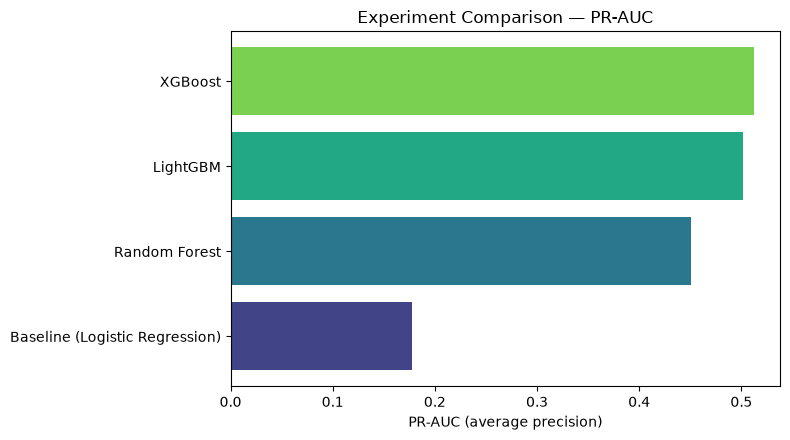

In [ ]:
plt.figure(figsize=(8, 4.5))
order = results_df.sort_values("pr_auc")
colors = sns.color_palette("viridis", len(order))
plt.barh(order["experiment"], order["pr_auc"], color=colors)
plt.xlabel("PR-AUC (average precision)")
plt.title("Experiment Comparison — PR-AUC")
plt.tight_layout()
plt.show()


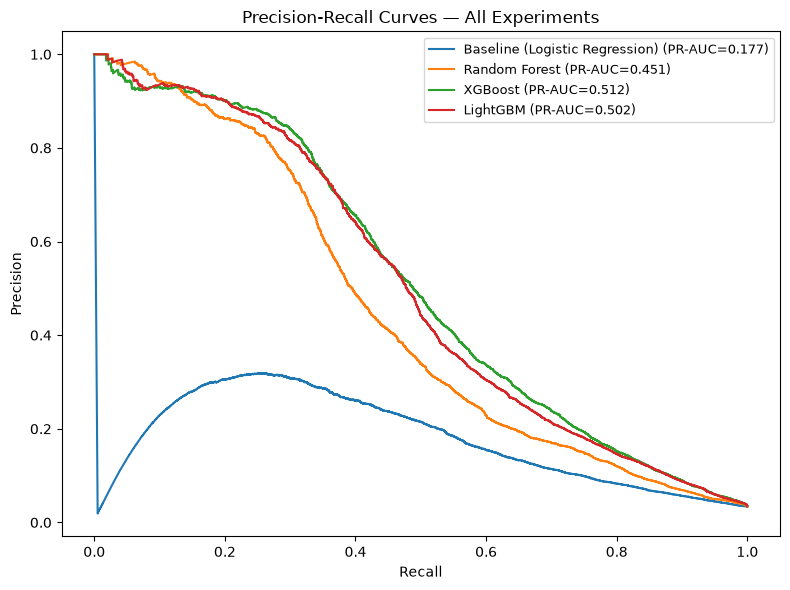

In [ ]:
plt.figure(figsize=(8, 6))
for r in results:
    precisions, recalls, _ = precision_recall_curve(y_val, r["probs"])
    plt.plot(recalls, precisions, label=f"{r['name']} (PR-AUC={r['pr_auc']:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves — All Experiments")
plt.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()


**Reading the PR curve plot:** a curve sitting consistently above another
is doing better across essentially every threshold choice, not just at
one specific operating point. Two curves that cross are more ambiguous —
one may be better for a "catch more fraud, accept more false alarms"
strategy, and the other better for the opposite, which is itself useful
information for `21_DECISION_ENGINE` later.

**Important caveat before picking a winner:** PR-AUC alone doesn't
capture everything that matters. A model with marginally higher PR-AUC
but a far larger review queue at the threshold you'd actually operate at
could be the worse business choice — that's the `25_BUSINESS_EVALUATION`
consideration, out of scope for this notebook but worth remembering
before treating the ranking below as final.


In [ ]:
best = results_df.iloc[0]
best_result = next(r for r in results if r["name"] == best["experiment"])

print(f"Best experiment by PR-AUC: {best['experiment']}")
print(f"PR-AUC: {best['pr_auc']:.4f}   ROC-AUC: {best['roc_auc']:.4f}")
print()
print("Classification report at default 0.5 threshold:")
print(classification_report(y_val, (best_result['probs'] >= 0.5).astype(int), digits=4))


Best experiment by PR-AUC: XGBoost
PR-AUC: 0.5122   ROC-AUC: 0.9002

Classification report at default 0.5 threshold:
              precision    recall  f1-score   support

         0.0     0.9894    0.9029    0.9442    114044
         1.0     0.2109    0.7279    0.3270      4064

    accuracy                         0.8969    118108
   macro avg     0.6001    0.8154    0.6356    118108
weighted avg     0.9626    0.8969    0.9230    118108



## Step 9: Save the Winning Model

Saved the same way the baseline was — model, scaler (if the winner needs
one), and feature list bundled together so a prediction can always be
reproduced consistently. We also record which experiment won and its
validation metrics as metadata, so this choice is traceable later.


In [ ]:
needs_scaling = "SMOTE" in best["experiment"] or "Baseline" in best["experiment"]

winning_artifact = {
    "model": best_result["model"],
    "scaler": scaler if needs_scaling else None,
    "imputer": imputer if needs_scaling else None,
    "feature_cols": feature_cols,
    "experiment_name": best["experiment"],
    "val_roc_auc": best["roc_auc"],
    "val_pr_auc": best["pr_auc"],
}

model_out_path = str(MODEL_DIR / "best_experiment_model.joblib")
joblib.dump(winning_artifact, model_out_path)

print("Saved winning model artifact to:")
print(" ", model_out_path)
print(f"Winner: {best['experiment']}  (needs_scaling={needs_scaling})")


Saved winning model artifact to:
  C:\Users\acer\Desktop\Programs\Projects_for _data_science\Fraud_Detection_Model\models\best_experiment_model.joblib
Winner: XGBoost  (needs_scaling=False)


## Summary

Ran five experiments on the identical time-based train/validation split
used by `05_baseline_model.ipynb`, varying two things independently:

- **Model family:** logistic regression (baseline) vs. Random Forest vs.
  XGBoost vs. LightGBM, all using class weighting for imbalance.
- **Imbalance technique:** class weighting (baseline) vs. SMOTE, both
  using the identical logistic regression model family.

The comparison table and precision-recall curves above show which
experiment generalizes best to held-out, chronologically later data — the
only kind of "best" that matters for a model that will eventually score
genuinely new transactions.

**What this notebook deliberately did not do:** extensive hyperparameter
tuning, combining techniques (e.g. XGBoost + SMOTE together), or a
business-cost-weighted threshold analysis. Those are reasonable next
steps if the winning direction here (a specific model family, or a
specific imbalance technique) looks promising enough to invest further
effort in.

**Next step:** `07_model_evaluation.ipynb` — a deeper evaluation of the
winning model specifically: calibration (per `20_RISK_SCORING`), a closer
look at the confusion matrix and threshold tradeoffs, and tying
performance back to the business cost framing from `12_BUSINESS_PROBLEM`.
